In [ ]:
#import libary
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

# EDA Dataset Klasifikasi Jaringan UNSW-NB15

Pada tugas ini saya menggunakan dataset **UNSW-NB15** yang saya ambil dari **Kaggle**. Dataset ini berisi data trafik jaringan yang dapat digunakan untuk membedakan trafik normal dan trafik yang termasuk serangan.

Tujuan EDA ini adalah untuk melihat kondisi dataset terlebih dahulu sebelum masuk ke tahap klasifikasi. Jadi, saya akan melihat isi data, ukuran data, data kosong, data duplikat, nilai-nilai yang mencurigakan, outlier, distribusi data, sampai hubungan antar fitur.

In [ ]:
df = pd.read_csv('/content/UNSW_NB15_testing-set.csv', encoding='latin1')

# Nama kolom ID pada file memiliki karakter BOM, jadi dirapikan agar lebih mudah digunakan.
if df.columns[0] != 'id':
    df.rename(columns={df.columns[0]: 'id'}, inplace=True)

df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,Normal,0.0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1.0,2.0,0.0,0.0,0.0,1.0,6.0,0.0,Normal,0.0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1.0,3.0,0.0,0.0,0.0,2.0,6.0,0.0,Normal,0.0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1.0,3.0,1.0,1.0,0.0,2.0,1.0,0.0,Normal,0.0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1.0,40.0,0.0,0.0,0.0,2.0,39.0,0.0,Normal,0.0


### Penjelasan

Dari output `head()` terlihat bahwa data memang berisi karakteristik trafik jaringan. Beberapa contoh kolomnya adalah `dur` untuk durasi koneksi, `proto` untuk protokol, `service` untuk layanan, `state` untuk kondisi koneksi, kemudian ada jumlah paket dan byte seperti `spkts`, `dpkts`, `sbytes`, dan `dbytes`.

Di bagian akhir terdapat `attack_cat` dan `label`. Kolom `label` akan menjadi bagian penting karena menunjukkan apakah trafik termasuk **Normal (0)** atau **Attack (1)**.

In [ ]:
df.tail()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
30158,30159,0.315579,tcp,ftp,FIN,52,54,2934,3742,332.721762,...,1.0,6.0,1.0,1.0,0.0,10.0,2.0,0.0,Normal,0.0
30159,30160,0.020178,tcp,-,FIN,40,42,2542,23508,4014.273068,...,1.0,1.0,0.0,0.0,0.0,4.0,3.0,0.0,Normal,0.0
30160,30161,0.068895,tcp,-,FIN,48,50,2958,32642,1407.939675,...,1.0,2.0,0.0,0.0,0.0,10.0,3.0,0.0,Normal,0.0
30161,30162,0.054925,tcp,-,FIN,66,68,3926,57474,2421.483911,...,1.0,1.0,0.0,0.0,0.0,2.0,4.0,0.0,Normal,0.0
30162,30163,0.046360,tcp,ftp-data,FIN,6,8,320,1910,280.414144,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Penjelasan

Dari `tail()` kita bisa melihat data pada bagian paling akhir dataset. Bentuk kolomnya tetap sama dengan data di bagian awal. Hal ini membantu memastikan bahwa file terbaca sampai bagian akhir dan tidak hanya berisi beberapa baris pertama saja.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30163 entries, 0 to 30162
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 30163 non-null  int64  
 1   dur                30163 non-null  float64
 2   proto              30163 non-null  object 
 3   service            30163 non-null  object 
 4   state              30163 non-null  object 
 5   spkts              30163 non-null  int64  
 6   dpkts              30163 non-null  int64  
 7   sbytes             30163 non-null  int64  
 8   dbytes             30163 non-null  int64  
 9   rate               30163 non-null  float64
 10  sttl               30163 non-null  int64  
 11  dttl               30163 non-null  int64  
 12  sload              30163 non-null  float64
 13  dload              30163 non-null  float64
 14  sloss              30163 non-null  int64  
 15  dloss              30163 non-null  int64  
 16  sinpkt             301

### Penjelasan

Dari hasil `info()` dapat dilihat bahwa dataset mempunyai **45 kolom** dan seluruh kolom terisi, sehingga jumlah nilai non-null pada setiap kolom adalah **175.341**.

Tipe datanya terdiri dari **30 kolom integer, 11 kolom float, dan 4 kolom object**. Kolom bertipe object merupakan data kategorikal seperti `proto`, `service`, `state`, dan `attack_cat`.

Jadi, dari tahap ini dapat dikatakan bahwa dataset sudah terbaca dengan baik dan tidak ditemukan data kosong dalam bentuk `NaN`.

In [ ]:
df.shape

(30163, 45)

### Penjelasan

Hasil `shape` adalah **(175341, 45)**. Artinya dataset ini mempunyai **175.341 baris data** dan **45 kolom**.

Jumlah barisnya cukup besar, sehingga dataset ini cukup baik untuk digunakan dalam analisis trafik jaringan. Empat puluh lima kolom tersebut berisi berbagai karakteristik dari koneksi jaringan dan label klasifikasinya.

In [ ]:
# ringkasan statistik buat kolom numerik
df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,30163.000000,30163.000000,30163.000000,30163.000000,30163.000000,3.016300e+04,3.016300e+04,30163.000000,30163.000000,3.016300e+04,...,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.0
mean,15082.000000,0.824833,37.169877,47.729934,4104.936280,3.932519e+04,3.141537e+03,36.513212,32.663661,3.505139e+06,...,1.805882,1.154035,3.191864,0.020158,0.020158,0.107254,4.463331,5.448843,0.001392,0.0
std,8707.452421,3.938513,61.809599,115.636641,7741.105866,1.546725e+05,1.271387e+04,34.700617,30.032546,4.160798e+07,...,2.988991,2.262991,4.325584,0.141013,0.141013,0.372456,3.853058,5.217028,0.037291,0.0
min,1.000000,0.000000,1.000000,0.000000,28.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.0
25%,7541.500000,0.004292,4.000000,4.000000,528.000000,3.040000e+02,1.983903e+02,31.000000,29.000000,8.901196e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.0
50%,15082.000000,0.027458,16.000000,18.000000,1684.000000,2.478000e+03,2.224720e+03,31.000000,29.000000,5.422469e+05,...,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,0.0
75%,22622.500000,0.276004,48.000000,50.000000,3744.000000,1.573600e+04,3.760452e+03,31.000000,29.000000,1.009558e+06,...,1.000000,1.000000,4.000000,0.000000,0.000000,0.000000,6.000000,7.000000,0.000000,0.0
max,30163.000000,59.175457,656.000000,1278.000000,68199.000000,1.641360e+06,1.000000e+06,255.000000,254.000000,2.461333e+09,...,46.000000,46.000000,63.000000,2.000000,2.000000,9.000000,46.000000,62.000000,1.000000,0.0


### Penjelasan

Dari statistik deskriptif, nilai pada fitur jaringan terlihat cukup bervariasi.

Contohnya, `dur` mempunyai nilai maksimum **60**, sedangkan `sbytes` bisa mencapai sekitar **12,97 juta byte** dan `dbytes` mencapai sekitar **14,66 juta byte**. Nilai maksimum yang jauh lebih besar dibandingkan nilai tengahnya menunjukkan bahwa beberapa koneksi mempunyai karakteristik yang sangat berbeda dari sebagian besar data.

Hal seperti ini cukup masuk akal pada data trafik jaringan karena ukuran paket, jumlah byte, dan beban trafik bisa sangat berbeda antara satu koneksi dengan koneksi lainnya.

In [ ]:
df.isnull().sum()

,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


### Penjelasan

Dari output `isnull().sum()` dapat dilihat bahwa **tidak ada missing value** pada seluruh kolom. Semua kolom mempunyai jumlah missing value **0**.

Jadi untuk dataset yang saya gunakan, tidak ada data yang perlu diisi atau diganti karena kosong. Ini membuat proses EDA menjadi lebih sederhana karena kita tidak perlu melakukan imputasi untuk `NaN`.

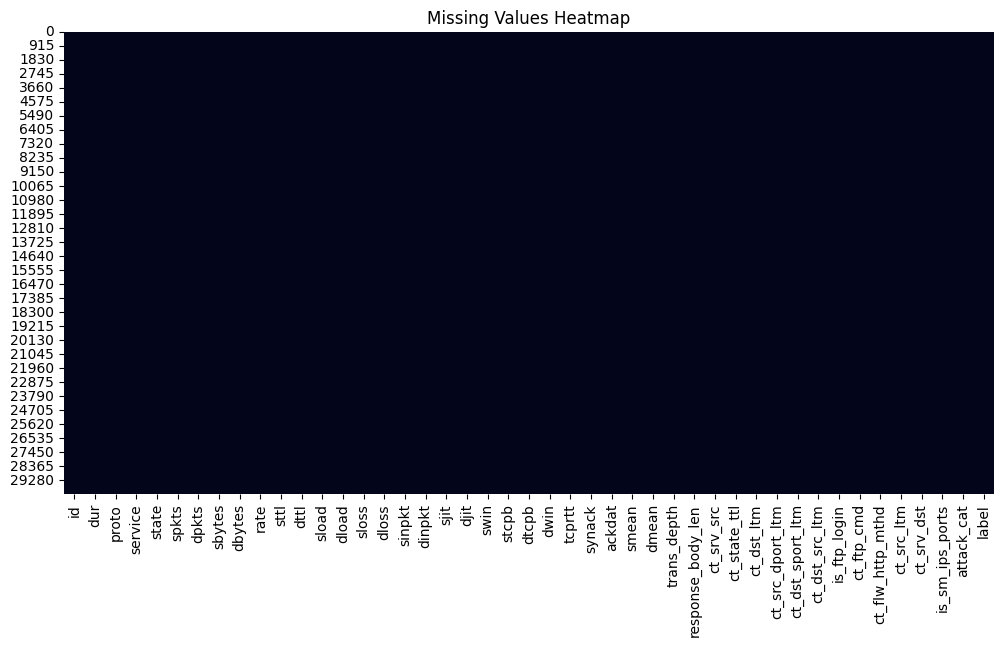

In [ ]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

### Penjelasan

Heatmap missing value terlihat kosong tanpa pola warna yang menunjukkan data kosong. Hasil visual ini sesuai dengan pemeriksaan sebelumnya, yaitu semua kolom memiliki **0 missing value**.

Jadi, bisa disimpulkan bahwa dari sisi nilai `NaN`, dataset ini dalam kondisi lengkap.

In [ ]:
df.duplicated().sum()

np.int64(0)

### Penjelasan

Hasil pemeriksaan menunjukkan jumlah data duplikat adalah **0 baris**.

Artinya, tidak ditemukan dua baris yang sama persis di dalam dataset. Jadi pada tahap ini tidak ada data yang perlu dihapus karena duplikasi.

## NILAI UNIK

Di bagian ini saya melihat nilai-nilai yang muncul di setiap kolom. Tujuannya supaya saya bisa memahami isi dataset, terutama pada kolom kategorikal seperti `proto`, `service`, `state`, dan `attack_cat`.

Dengan melihat nilai unik, kita juga bisa mengetahui apakah ada nilai yang aneh atau terlalu banyak variasinya.

In [ ]:
for col in df.columns:
    print(f"Unique values in column '{col}' : ")
    print(df[col].unique())
    print("-" * 30)

Unique values in column 'id' : 
[    1     2     3 ... 30161 30162 30163]
------------------------------
Unique values in column 'dur' : 
[0.121478 0.649902 1.623129 ... 0.068895 0.054925 0.04636 ]
------------------------------
Unique values in column 'proto' : 
['tcp' 'udp' 'arp' 'ospf' 'icmp' 'igmp' 'rtp']
------------------------------
Unique values in column 'service' : 
['-' 'ftp' 'smtp' 'snmp' 'http' 'ftp-data' 'dns' 'ssh']
------------------------------
Unique values in column 'state' : 
['FIN' 'INT' 'CON' 'ECO' 'REQ' 'RST' 'PAR' 'URN' 'no']
------------------------------
Unique values in column 'spkts' : 
[  6  14   8  12  10  62   2  24  28  30   1  16   4  36  22 122  38  20
  66  78  42  52  64  40  80   3  26 110 106 360 354 366 352 108 362  18
 342 332 336 308 322 328 358 224 234 222 208 200  68  48  90 356  70 348
 236  92 240 452 450 368 434 420 238 432 288 112 650 656 364 548  50 230
 562 372 216 204  60 228 206 350 294 346 232  46 226 218 296 190 286  88
 338  32 344 

### Penjelasan

Output nilai unik memang cukup panjang karena dataset mempunyai **45 kolom**. Beberapa hasil yang paling penting adalah:

- `proto` mempunyai **133 nilai unik**, sehingga jenis protokol yang ada cukup beragam.
- `service` mempunyai **13 nilai unik**.
- `state` mempunyai **9 nilai unik**.
- `attack_cat` mempunyai **10 nilai unik**.
- `label` hanya mempunyai **2 nilai unik**, yaitu **0 dan 1**.

Dari sini terlihat bahwa `label` cocok digunakan sebagai target klasifikasi biner, sedangkan kolom seperti `proto`, `service`, dan `state` merupakan fitur kategorikal.

## SUSPECTS VALUE

Di bagian ini saya mencari nilai yang biasanya dipakai sebagai tanda bahwa suatu data tidak diketahui, kosong, atau merupakan placeholder.

Saya menggunakan daftar `suspects` berikut sesuai format yang diberikan:

`'?', '??', 'NA', 'N/A', 'na', 'None', 'null', 'Null', 'Unknown', 'UNK', '-', '--', ' ', 'Nan', 'XXX', 'unk', 9999, -9999`

Yang penting, kalau suatu nilai ditemukan, saya tidak langsung menganggapnya salah. Saya melihat dulu **muncul di kolom mana dan berapa kali muncul**.

In [ ]:
suspects = ['?', '??', 'NA', 'N/A', 'na', 'None', 'null', 'Null', 'Unknown', 'UNK', '-', '--', ' ', 'Nan', 'XXX', 'unk', 9999, -9999]

for val in suspects:
    print(f"{val}:")
    print((df == val).sum())
    print()

?:
id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_c

### Penjelasan SUSPECTS VALUE berdasarkan hasil dataset

Dari hasil pemeriksaan, sebagian besar nilai pada daftar `suspects` **tidak ditemukan**.

Ada tiga hasil yang benar-benar muncul:

**1. Nilai `-` ditemukan sebanyak 94.168 kali pada kolom `service`.**

Jadi, tanda `-` di dataset ini bukan berarti seluruh baris rusak. Nilai tersebut muncul pada kolom `service`, yang menunjukkan bahwa service tidak dicatat atau tidak teridentifikasi pada koneksi tersebut. Karena jumlahnya sangat banyak, menghapus semua baris yang mempunyai `-` justru akan membuang sebagian besar data.

**2. Nilai `9999` ditemukan 1 kali pada kolom `id`.**

Nilai ini adalah nomor ID pada salah satu baris, sehingga `9999` di kolom ID bukan otomatis merupakan missing value. Ini lebih tepat dianggap sebagai angka ID biasa.

**3. Nilai `9999` juga ditemukan 1 kali pada kolom `sbytes`.**

Pada baris tersebut, `sbytes = 9999` benar-benar merupakan nilai byte yang tercatat. Jadi, kita juga tidak boleh langsung menghapusnya hanya karena kebetulan angka tersebut masuk ke daftar suspect.

Sementara itu, nilai seperti `?`, `??`, `NA`, `N/A`, `None`, `null`, `Unknown`, `UNK`, `--`, spasi kosong, `Nan`, `XXX`, `unk`, dan `-9999` **tidak ditemukan** pada dataset ini.

Jadi kesimpulan dari SUSPECTS VALUE adalah: **dataset tidak mempunyai placeholder missing yang umum seperti `NA` atau `Unknown`. Tanda `-` memang ada, tetapi konteksnya berada di kolom `service`, sehingga sebaiknya tidak langsung dihapus.**

## OUTLIER

Outlier adalah nilai yang letaknya cukup jauh dari sebagian besar data. Di data jaringan, adanya outlier belum tentu berarti data salah. Trafik serangan atau koneksi tertentu memang bisa mempunyai jumlah byte, paket, atau beban trafik yang jauh lebih besar.

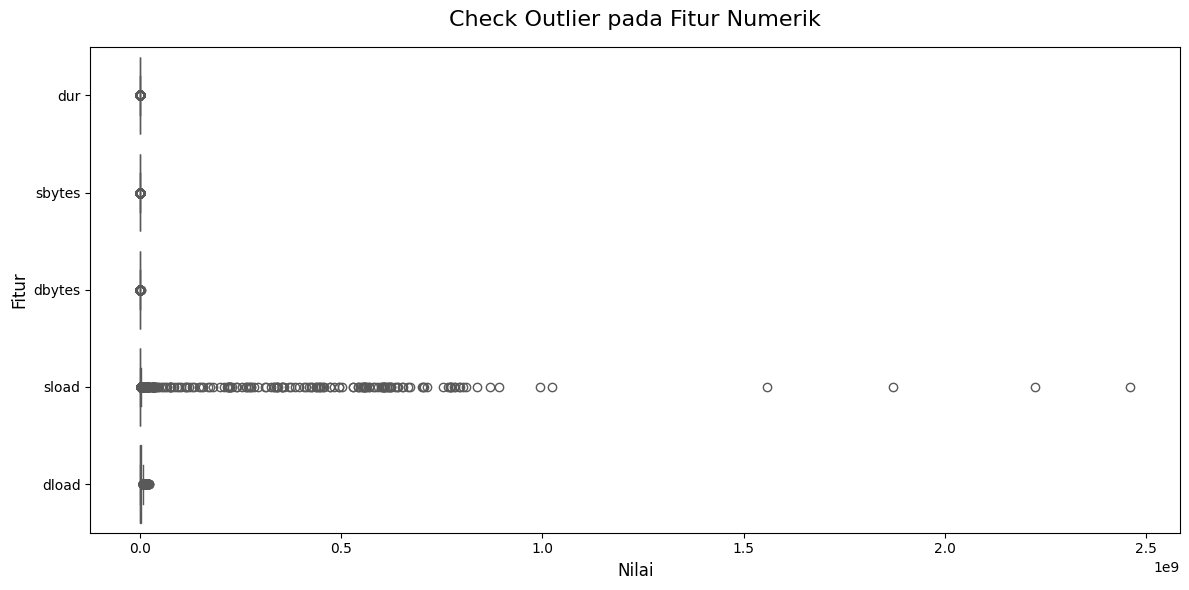

In [ ]:
num_cols = ['dur', 'sbytes', 'dbytes', 'sload', 'dload']

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[num_cols], orient='h', palette='Set2')

plt.title('Check Outlier pada Fitur Numerik', fontsize=16, pad=15)
plt.xlabel('Nilai', fontsize=12)
plt.ylabel('Fitur', fontsize=12)

plt.tight_layout()
plt.show()

### Penjelasan

Dari boxplot terlihat bahwa beberapa fitur mempunyai nilai yang sangat jauh dari sebagian besar datanya.

Untuk memberikan gambaran yang lebih jelas, jika menggunakan aturan IQR, jumlah nilai yang terdeteksi sebagai outlier adalah:

- `dur`: **15.741 data (sekitar 8,98%)**
- `sbytes`: **22.873 data (sekitar 13,04%)**
- `dbytes`: **28.131 data (sekitar 16,04%)**
- `sload`: **13.518 data (sekitar 7,71%)**
- `dload`: **38.143 data (sekitar 21,75%)**

Nilai outlier paling banyak terdapat pada `dload`. Walaupun begitu, data tersebut tidak langsung saya hapus karena dalam konteks jaringan, trafik yang sangat tinggi bisa saja memang menunjukkan karakteristik serangan atau aktivitas jaringan tertentu.

/tmp/ipykernel_1201/3644583402.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


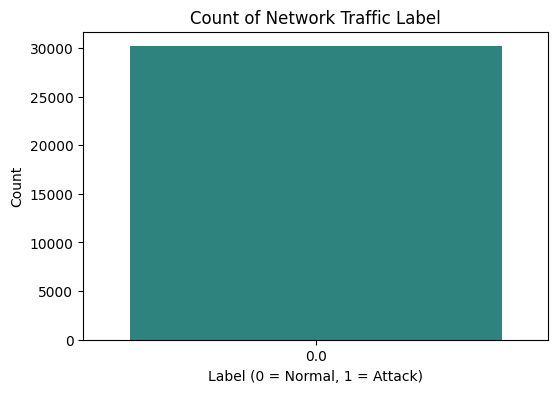

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Count of Network Traffic Label')
plt.xlabel('Label (0 = Normal, 1 = Attack)')
plt.ylabel('Count')
plt.show()

### Penjelasan

Dari grafik `label`, jumlah data **Attack (1) adalah 119.341 data**, sedangkan **Normal (0) adalah 56.000 data**.

Kalau dihitung dalam persentase:

- **Attack = 68,06%**
- **Normal = 31,94%**

Artinya dataset ini lebih banyak berisi trafik serangan dibandingkan trafik normal. Jadi distribusi kelasnya **tidak seimbang**.

Hal ini perlu diperhatikan ketika nanti dataset digunakan untuk membuat model klasifikasi, karena model bisa saja lebih mudah mempelajari kelas Attack yang jumlah datanya lebih banyak.

array([[<Axes: title={'center': 'dur'}>,
        <Axes: title={'center': 'sbytes'}>],
       [<Axes: title={'center': 'dbytes'}>,
        <Axes: title={'center': 'sload'}>],
       [<Axes: title={'center': 'dload'}>, <Axes: >]], dtype=object)

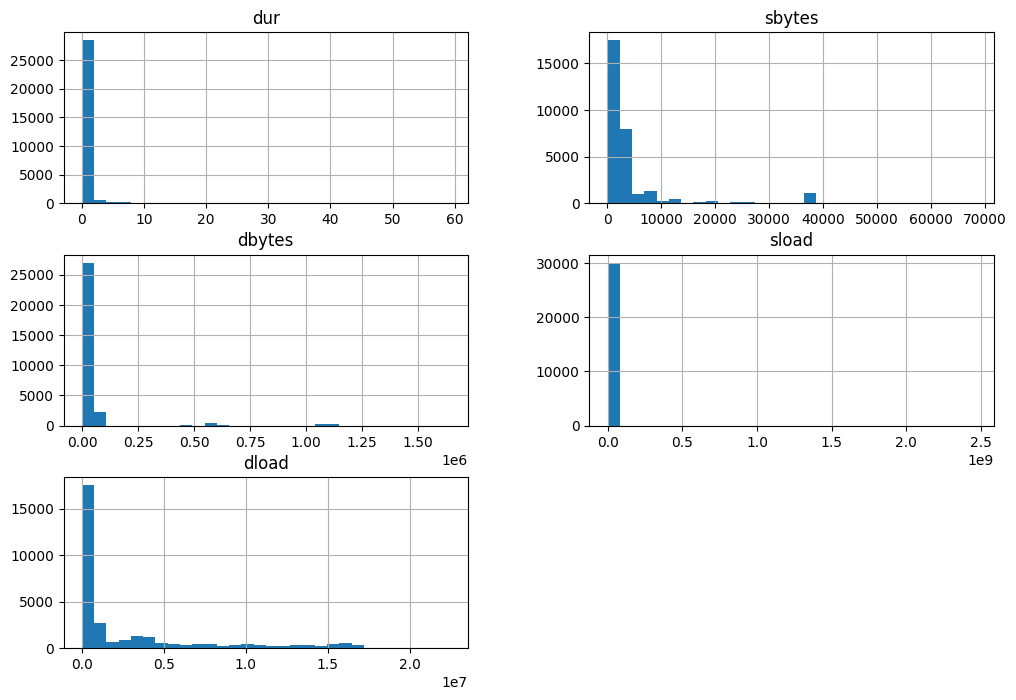

In [ ]:
df[num_cols].hist(figsize=(12,8), bins=30)

### Penjelasan

Histogram menunjukkan bahwa distribusi fitur numerik tidak semuanya berbentuk merata. Beberapa fitur terlihat menumpuk di nilai yang relatif kecil, tetapi mempunyai ekor panjang ke kanan karena terdapat beberapa nilai yang sangat besar.

Pola tersebut sejalan dengan hasil boxplot sebelumnya. Jadi, data trafik jaringan memang mempunyai variasi yang cukup besar dan tidak semuanya mengikuti distribusi normal.

## DISTRIBUSI FITUR KATEGORIKAL

Selanjutnya saya melihat jumlah nilai unik dan frekuensi kemunculan pada fitur kategorikal.

- `proto` menunjukkan protokol jaringan.
- `service` menunjukkan layanan jaringan.
- `state` menunjukkan kondisi koneksi.
- `attack_cat` menunjukkan kategori trafik atau jenis serangan.
- `label` menunjukkan Normal atau Attack.


proto unique values: 7
proto
tcp     21869
udp      8119
arp       114
ospf       46
icmp       13
igmp        1
rtp         1
Name: count, dtype: int64

service unique values: 8
service
-           17256
dns          5327
http         2927
ftp-data     1811
smtp         1126
ssh          1101
ftp           614
snmp            1
Name: count, dtype: int64

state unique values: 9
state
FIN    21797
CON     7906
INT      335
RST       70
REQ       42
ECO       10
PAR        1
URN        1
no         1
Name: count, dtype: int64

attack_cat unique values: 1
attack_cat
Normal    30162
Name: count, dtype: int64

label unique values: 1
label
0.0    30162
Name: count, dtype: int64


/tmp/ipykernel_1201/57250253.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


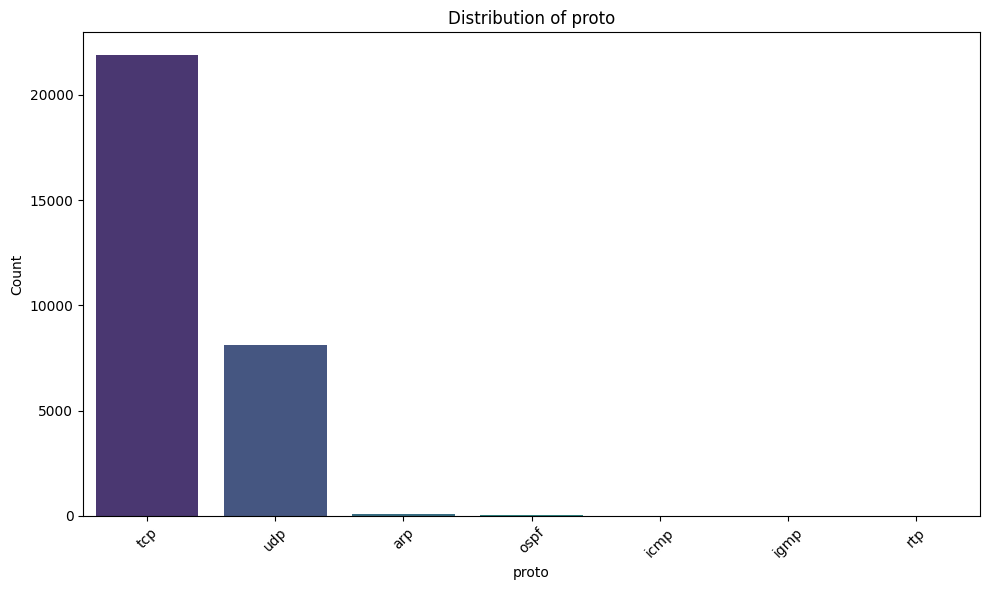

/tmp/ipykernel_1201/57250253.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


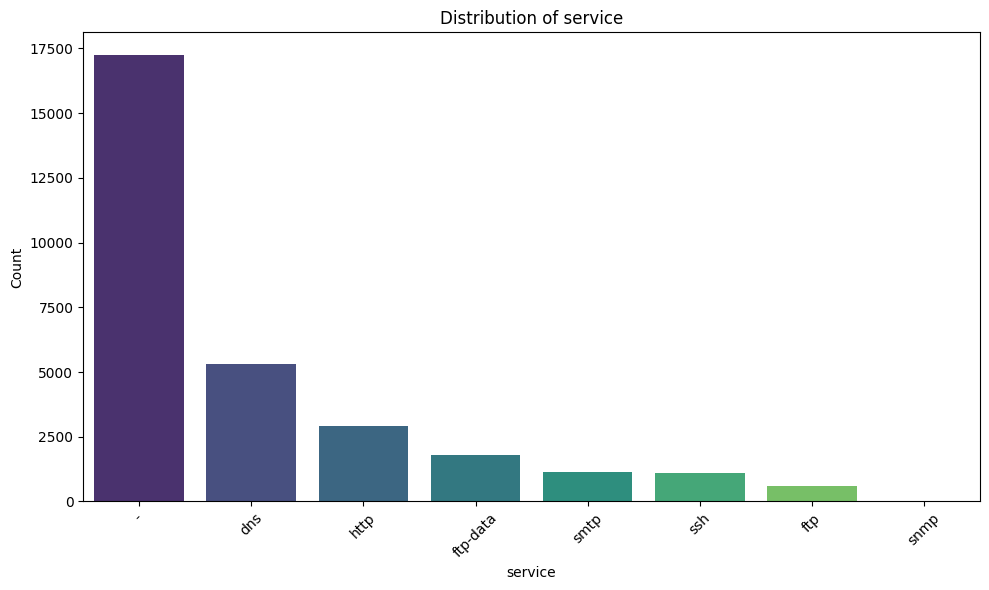

/tmp/ipykernel_1201/57250253.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


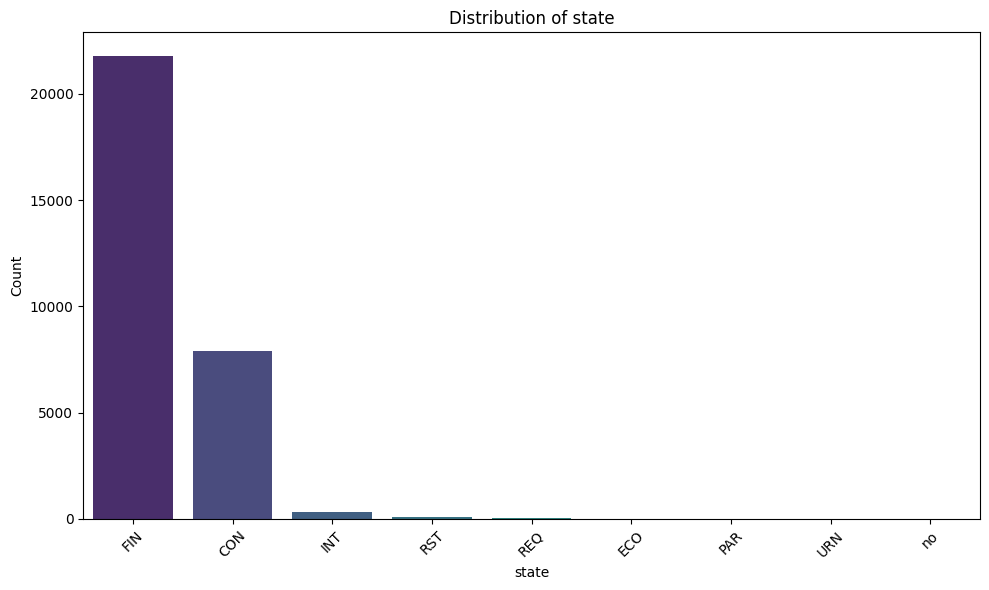

/tmp/ipykernel_1201/57250253.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


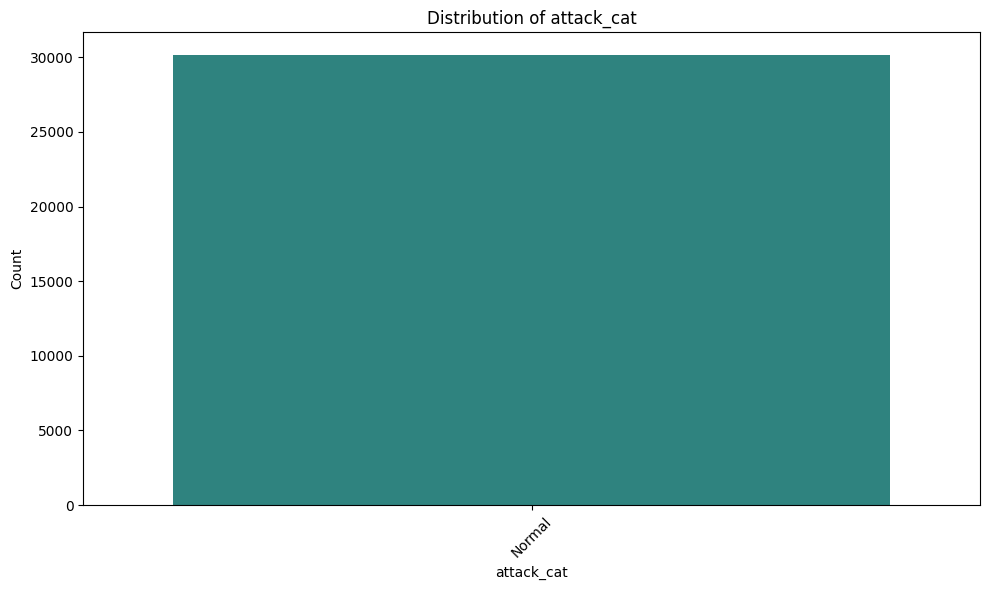

/tmp/ipykernel_1201/57250253.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


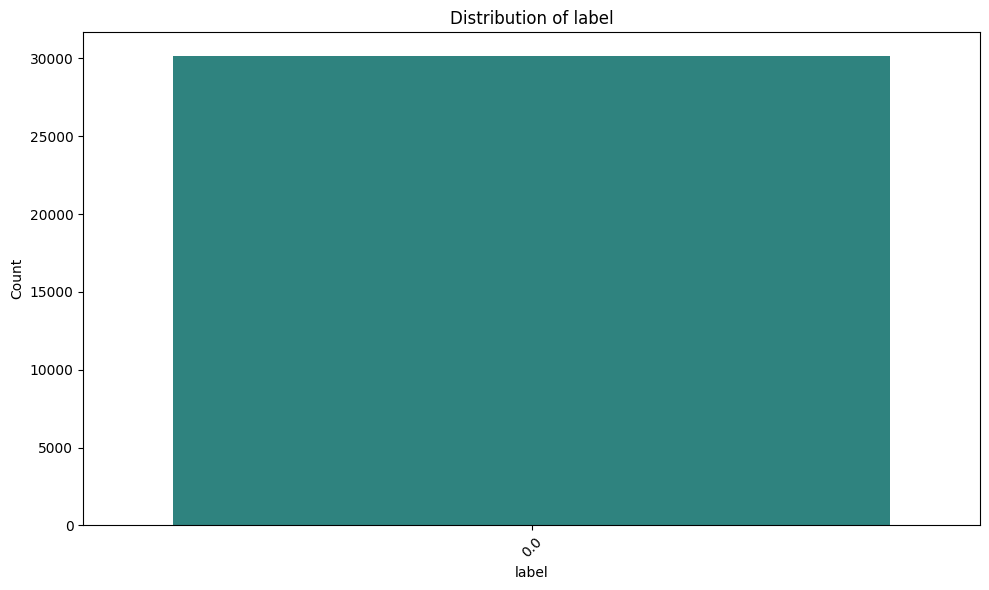

In [ ]:
cat_cols = ['proto', 'service', 'state', 'attack_cat', 'label']

for col in cat_cols:
    print(f"\n{col} unique values:", df[col].nunique())
    print(df[col].value_counts().head(10))

for col in cat_cols:
    if df[col].nunique() < 50:
        plt.figure(figsize=(10, 6))
        sns.countplot(
            data=df,
            x=col,
            order=df[col].value_counts().index,
            palette='viridis'
        )
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Skipping plot for '{col}' due to high number of unique values ({df[col].nunique()})")

### Penjelasan

Dari hasil distribusi kategori terlihat bahwa `proto` mempunyai kategori yang sangat banyak, yaitu **133 protokol**. Beberapa yang paling sering muncul adalah `tcp` sebanyak **79.946**, `udp` sebanyak **63.283**, dan `unas` sebanyak **12.084**.

Pada `service` terdapat **13 kategori**. Tiga yang paling banyak adalah `-` sebanyak **94.168**, `dns` sebanyak **47.294**, dan `http` sebanyak **18.724**.

Untuk `state`, jumlah kategori ada **9**, dengan `INT` sebanyak **82.275** dan `FIN` sebanyak **77.825** sebagai dua kategori yang paling banyak.

Sedangkan `attack_cat` mempunyai **10 kategori**. Kategori terbesar setelah `Normal` adalah `Generic` sebanyak **40.000**, kemudian `Exploits` sebanyak **33.393**, dan `Fuzzers` sebanyak **18.184**.

Hasil ini menunjukkan bahwa jenis trafik dan serangan pada dataset cukup beragam.

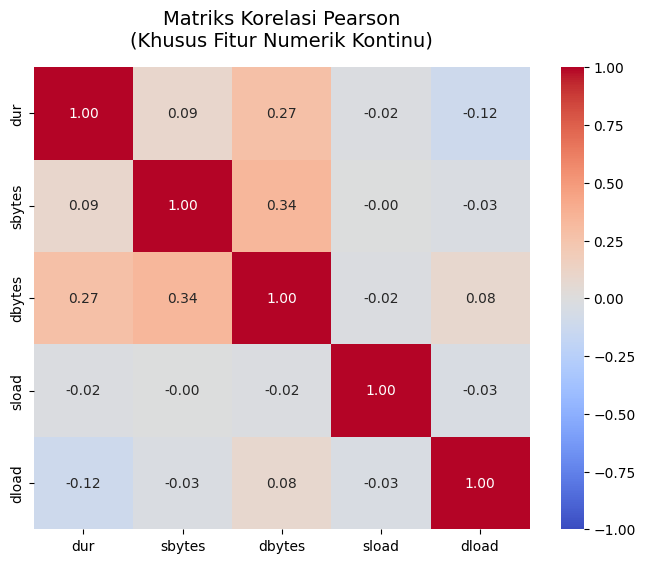

In [ ]:
plt.figure(figsize=(8,6))

pearson_matrix = df[num_cols].corr(method='pearson')

sns.heatmap(
    pearson_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Matriks Korelasi Pearson\n(Khusus Fitur Numerik Kontinu)', fontsize=14, pad=15)
plt.show()

### Penjelasan

Dari matriks Pearson, hubungan yang paling terlihat adalah antara `dur` dan `sbytes` dengan korelasi sekitar **0,20**, kemudian `dur` dan `dbytes` sekitar **0,14**.

Sementara hubungan `sload` dengan fitur numerik lainnya cenderung rendah atau negatif, misalnya `sload` dengan `dload` sekitar **-0,11**.

Secara umum, korelasi antar lima fitur yang dipilih tidak terlalu tinggi. Artinya tidak ada pasangan fitur yang memiliki hubungan linear sangat kuat pada subset fitur ini.

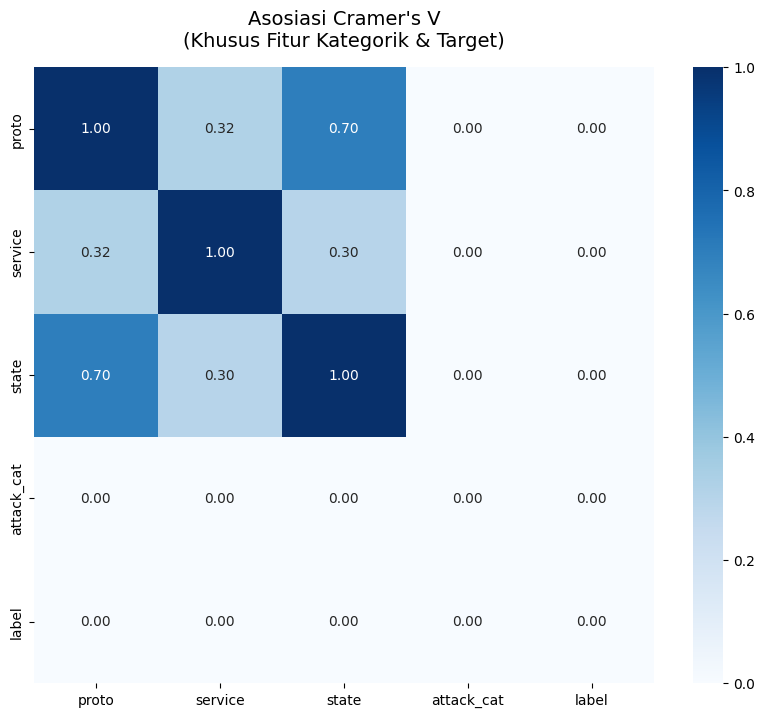

In [ ]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, c = confusion_matrix.shape

    if min(r-1, c-1) == 0:
        return 0.0

    return np.sqrt((chi2 / n) / min(r-1, c-1))


cramer_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols)

for col1 in cat_cols:
    for col2 in cat_cols:
        cramer_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

cramer_matrix = cramer_matrix.astype(float)

plt.figure(figsize=(10,8))

sns.heatmap(
    cramer_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    vmin=0,
    vmax=1
)

plt.title("Asosiasi Cramer's V\n(Khusus Fitur Kategorik & Target)", fontsize=14, pad=15)
plt.show()

### Penjelasan

Cramer's V digunakan untuk melihat hubungan antara variabel kategorikal.

Hubungan yang paling kuat dengan `label` pada hasil ini adalah:

- `state` dengan `label` = **0,56**, sehingga hubungannya tergolong cukup kuat.
- `proto` dengan `label` = **0,44**, sehingga juga mempunyai hubungan yang cukup terlihat.
- `service` dengan `label` = **0,27**, sehingga hubungannya lebih lemah dibandingkan dua variabel sebelumnya.
- `attack_cat` dengan `label` = **1,00**.

Nilai `attack_cat` menjadi **1,00** karena kategori `attack_cat` memang sangat berkaitan langsung dengan label Normal/Attack. Karena itu, `attack_cat` sebaiknya **tidak digunakan sebagai fitur input ketika membuat model klasifikasi biner**, supaya model tidak mendapatkan jawaban secara langsung dari kolom tersebut.

/tmp/ipykernel_1201/2111834576.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1201/2111834576.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1201/2111834576.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1201/2111834576.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1201/2111834576.py:10: FutureWarning: 

P

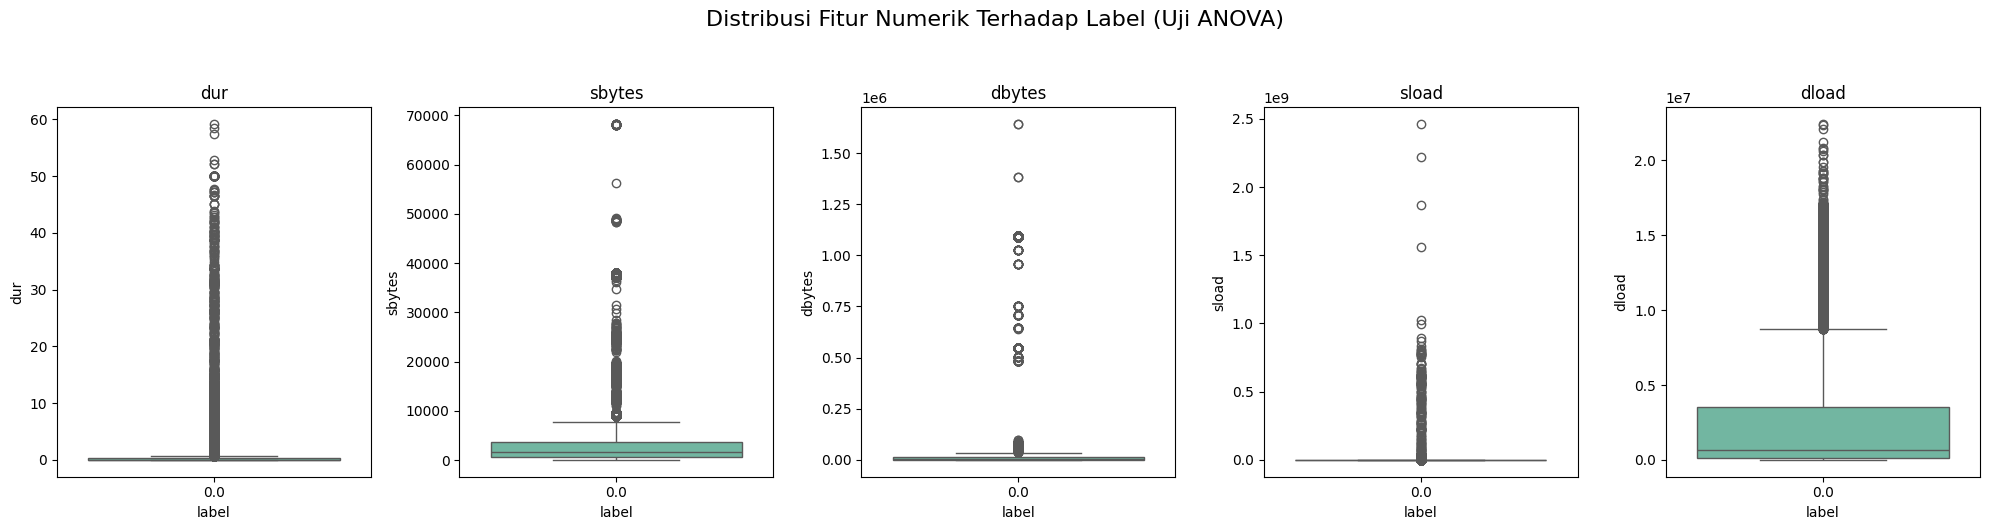

In [ ]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(20,5))

fig.suptitle(
    'Distribusi Fitur Numerik Terhadap Label (Uji ANOVA)',
    fontsize=16,
    y=1.05
)

for i, col in enumerate(num_cols):
    sns.boxplot(
        x='label',
        y=col,
        data=df,
        ax=axes[i],
        palette='Set2'
    )

    group0 = df[df['label'] == 0][col].dropna()
    group1 = df[df['label'] == 1][col].dropna()

    if len(group0) > 0 and len(group1) > 0:
        f_stat, p_val = f_oneway(group0, group1)
        axes[i].set_title(f"{col}\n(P-Value: {p_val:.4g})")
    else:
        axes[i].set_title(col)

plt.tight_layout()
plt.show()

### Penjelasan

Dari hasil uji ANOVA, semua lima fitur numerik yang diuji mempunyai **p-value sangat kecil**, yaitu:

- `dur` = **7,29 × 10⁻⁵²**
- `sbytes` = **7,31 × 10⁻¹⁵**
- `dbytes` = **5,50 × 10⁻²²⁸**
- `sload` = **0** pada tampilan Python karena nilainya sangat kecil
- `dload` = **0** pada tampilan Python karena nilainya sangat kecil

Karena seluruh p-value jauh lebih kecil dari **0,05**, berarti terdapat perbedaan yang signifikan antara nilai fitur tersebut pada trafik Normal dan Attack.

Kalau dilihat dari nilai statistik F, `dload` mempunyai nilai F paling besar, yaitu sekitar **32.170**, kemudian `sload` sekitar **6.066**. Ini menunjukkan bahwa kedua fitur tersebut mempunyai perbedaan yang cukup kuat antara kelompok Normal dan Attack.

Namun hasil ANOVA tidak berarti sebuah fitur pasti menjadi penyebab serangan. Hasil ini hanya menunjukkan bahwa distribusinya berbeda secara statistik antara kedua kelompok.

# KESIMPULAN EDA

Dari seluruh proses EDA yang dilakukan, saya mendapatkan beberapa gambaran penting tentang dataset UNSW-NB15.

Dataset yang digunakan mempunyai **175.341 baris dan 45 kolom**. Tidak ditemukan **missing value**, sehingga tidak ada data kosong yang harus diisi. Selain itu, jumlah data duplikat juga **0**, jadi tidak ditemukan baris yang sama persis.

Pada pemeriksaan **SUSPECTS VALUE**, tanda `-` ditemukan sebanyak **94.168 kali pada kolom `service`**. Nilai ini tidak langsung saya anggap sebagai data rusak karena memang muncul sebagai kategori service. Nilai `9999` juga ditemukan masing-masing satu kali pada `id` dan `sbytes`, tetapi keduanya masih merupakan nilai yang tercatat di dalam konteks kolom tersebut.

Distribusi label menunjukkan bahwa **119.341 data (68,06%) adalah Attack** dan **56.000 data (31,94%) adalah Normal**. Jadi dataset lebih banyak berisi trafik serangan.

Dari boxplot terlihat adanya cukup banyak nilai ekstrem pada fitur numerik. Hal ini tidak langsung dianggap sebagai kesalahan karena trafik jaringan memang bisa mempunyai nilai yang sangat tinggi.

Hasil korelasi Pearson menunjukkan hubungan linear antar lima fitur numerik yang dipilih relatif rendah. Sementara itu, Cramer's V menunjukkan bahwa `state` dan `proto` cukup berhubungan dengan `label`. Uji ANOVA juga menunjukkan bahwa kelima fitur numerik yang diuji mempunyai perbedaan yang signifikan antara kelompok Normal dan Attack.

Secara keseluruhan, dataset UNSW-NB15 cukup menarik untuk digunakan pada klasifikasi trafik jaringan karena mempunyai jumlah data yang besar, fitur numerik dan kategorikal yang beragam, serta label yang membedakan trafik normal dan serangan.

**Catatan:** jika nanti masuk ke tahap pembuatan model klasifikasi biner, kolom `attack_cat` sebaiknya tidak dimasukkan sebagai fitur karena hubungannya dengan `label` sangat langsung dan dapat menyebabkan data leakage.